In [1]:
# Colab Setup (Run this first)
# !pip install litebird_sim rich
# SMARTIES requires Python >= 3.13 and is not available on PyPI:
# !pip install "smarties @ git+https://github.com/simonsobs/smarties.git@9e9031f6e8ff220e22e3599c8f6d578e045a34d5"

# `litebird_sim` + SMARTIES

This notebook feeds the harmonic maps ($h_{n,m}$) computed by `litebird_sim` into [SMARTIES](https://github.com/simonsobs/smarties) to estimate the effect og beam convolution systematics at the map level, then compares the result with a full 4$\pi$ beam convolution.

The workflow is:

1. simulate a short scan and generate the CMB and beam alms;
2. convolve the TODs and bin them into a reference map;
3. compute the $h_{n,m}$ maps and read them with SMARTIES;
4. apply the SMARTIES beam systematics and compare the maps.

SMARTIES, and the formalism to perform beam convolution with it are described in: 
- The Simons Observatory Collaboration, *The Simons Observatory: A framework for efficient map-based simulations of instrumental systematics for CMB surveys* (in preparation).
- Demay, M., Morshed, M., Gerbino, M., & Pagano, L., *Exact map-space beam convolution via spin-mapmaking*, [arXiv:2610.20231](https://arxiv.org/abs/2610.20231) (2026).

To run this notebook you need `litebird_sim`, `healpy`, `matplotlib`, and [SMARTIES](https://github.com/simonsobs/smarties). SMARTIES is not available on PyPI and requires Python >= 3.13.

- On Google Colab, run the installation cell above.
- Locally, create a virtual environment and install the dependencies:

    ```
    python -m venv ./my_venv
    source ./my_venv/bin/activate
    pip install jupyter litebird_sim matplotlib
    pip install "smarties @ git+https://github.com/simonsobs/smarties.git@9e9031f6e8ff220e22e3599c8f6d578e045a34d5"
    ```

    If you have a local clone of the `litebird_sim` repository, you can use a development install instead: `pip install -e .`

## Imports

We import `litebird_sim` together with the SMARTIES modules used below.

In [2]:
import litebird_sim as lbs
import numpy as np
import matplotlib.pyplot as plt
import astropy
import astropy.time
import healpy as hp
import smarties as sm
from smarties.sky.convolution import get_beam_convolution_spins_maps

%matplotlib inline

## Parameters of the simulation

We simulate four 40 GHz LFT detectors (two polarimeters) over five days. The short duration keeps the example fast. The detectors are given a large, elliptical Gaussian beam so that the beam systematics computed by SMARTIES are clearly visible. See the [documentation](https://litebird-sim.readthedocs.io/en/latest/simulations.html#simulations) for more details about the input parameters.

In [3]:
telescope = "LFT"
channel = "L1-040"
detlist = [
    "000_000_003_QA_040_T",
    "000_000_003_QA_040_B",
    "000_000_004_QB_040_T",
    "000_000_004_QB_040_B",
]

start_time = 0
mission_time_days = 5

imo_version = "vPTEP"

# Resolution of the output maps
nside = 64

# Parameters of the (elliptical) beams
fwhm_arcmin = 200.0
ellipticity = 1.3
ellipse_angle = np.random.uniform(0, 2 * np.pi, 4)
pol_angles = [0.1, np.pi / 2, -0.08 + np.pi / 4, 3 * np.pi / 4]

# Parameters for the generation of the input CMB and for the convolution
lmax = 2 * nside
mmax = 4

## Simulation setup

We use the bundled PTEP IMO and simulate a five-day scan.

In [4]:
# This is the folder where the final report with the results of the simulation will be saved
base_path = ".test"

imo = lbs.Imo(flatfile_location=lbs.PTEP_IMO_LOCATION)

# initializing the simulation
sim = lbs.Simulation(
    base_path=base_path,
    imo=imo,
    start_time=start_time,
    duration_s=mission_time_days * 24 * 3600.0,
    random_seed=12345,  # seed for the random number generator (MANDATORY parameter!!!)
)

# Load the definition of the instrument (LFT)
sim.set_instrument(
    lbs.InstrumentInfo.from_imo(
        imo,
        f"/releases/{imo_version}/satellite/{telescope}/instrument_info",
    )
)

# Read the detectors in detlist and override their beam parameters
dets: list[lbs.DetectorInfo] = []
for n_det in detlist:
    det = lbs.DetectorInfo.from_imo(
        url=f"/releases/{imo_version}/satellite/{telescope}/{channel}/{n_det}/detector_info",
        imo=imo,
    )

    # we overwrite the nominal sampling rate read from IMO with a smaller one
    det.sampling_rate_hz = 30

    det.ellipticity = ellipticity
    det.fwhm_arcmin = fwhm_arcmin
    det.pol_angle_rad = pol_angles[detlist.index(n_det)]
    det.psi_rad = ellipse_angle[detlist.index(n_det)]
    dets.append(det)

# Generate the quaternions describing how the instrument moves in the Ecliptic reference frame
sim.set_scanning_strategy(
    imo_url=f"/releases/{imo_version}/satellite/scanning_parameters/"
)

20-Oct-26 15:54:19 WARNING root: MPI layer is already initialized. Reinitializing the entire RNG hierarchy.
20-Oct-26 15:54:19 WARNING root: MPI layer is already initialized. Reinitializing the entire RNG hierarchy.


In [5]:
(obs,) = sim.create_observations(
    detectors=dets,
    n_blocks_det=1,
    n_blocks_time=1,
    tods=[
        lbs.TodDescription(
            name="convolve_sky",
            units=lbs.Units.uK_CMB,
            description="CMB",
            dtype=np.float64,
        ),
    ],
)

sim.prepare_pointings()

## Generate inputs and convolve the TODs

We generate the input CMB alms and Gaussian beam alms, then convolve them into the TODs at pixel-center pointings. This 4$\pi$ convolution is the reference for the SMARTIES comparison.

In [6]:
# Generate the input CMB alms
sky_params = lbs.SkyGenerationParams(
    make_cmb=True,
    make_fg=False,
    seed_cmb=1,  # set this seed if you want to fix the CMB realization
    apply_beam=False,
    bandpass_integration=False,
    units="uK_CMB",
    output_type="alm",
    lmax=lmax,
)

alm_sky = sim.get_sky(parameters=sky_params)

# Synthesize the beam alms from the detector parameters
blms = sim.get_gauss_beam_alms(lmax=lmax, mmax=mmax, store_in_observation=True)

In [7]:
# Set up the beam convolution parameters
Convparams = lbs.BeamConvolutionParameters(
    lmax=lmax,
    mmax=mmax,
    single_precision=False,
    epsilon=1e-13,
)

# Convolve the alms in the TODs
sim.nullify_tod(components=["convolve_sky"])
sim.convolve_sky(
    sky_alms=alm_sky,
    beam_alms=blms,
    convolution_params=Convparams,
    component="convolve_sky",
    nside_centering=nside,
)

# Bin the TODs into the reference map
output_convolution = sim.make_binned_map(nside=nside, components=["convolve_sky"])
four_pi_convolved_map = output_convolution.binned_map

## H-maps from `litebird_sim`

The $h_{n,m}$ harmonic maps encode the detector pointings and are the input to SMARTIES. They are computed from the observations with `lbs.make_h_maps` and saved as HDF5 files.

`litebird_sim` writes one file per detector, `h_maps_det_<name>.h5`, with one group `"n,m"` per spin. Each group stores the real and imaginary parts of the $h$-map. In this example there is no half-wave plate, so only $m = 0$ is used, which is the case currently supported by SMARTIES.

In [8]:
spins = np.array([[0, 0], [2, 0], [4, 0], [6, 0], [8, 0]])

result_hmap = lbs.make_h_maps(
    sim.observations,
    nside,
    n_m_couples=spins,
    save_to_file=True,
    output_directory=".test",
)

## Reading the h-maps with SMARTIES


`build_mask_from_lbs_h_maps` returns the pixels observed by at least one detector. `read_lbs_h_maps` reads the requested spins $(n, 0)$ for $n = 0, 2, 4, 6, 8$, together with
$h_0$, and normalises the maps so that $\sum_d h^d_0 = 1$ in every pixel: $h^d_0$ is then the
relative weight of detector $d$, and $h^d_n = h^d_0 \langle e^{in\psi} \rangle_d$. 
Since there is no half-wave plate, the $(n, 0)$ keys are reduced to the integer spins $n$.

In [9]:
# The (0,0) spin gives the hit map (used as mask), the other spins the harmonic maps
h_maps_names = [".test/h_maps_det_" + det.name for det in dets]

mask_hits, detectors_hits = sm.io.build_mask_from_lbs_h_maps(
    h_maps_names,
    format_file="h5",
    spin_to_read=(0, 0),
    return_detectors_hits=True,
)

h_maps = sm.io.read_lbs_h_maps(
    h_maps_names,
    list_spin=spins,
    prefix="h_maps_det_",
    list_weights=None,
    mask=mask_hits,
    format_file="h5",
    single_precision=False,  # np.complex128
)

100%|██████████| 4/4 [00:00<00:00, 39.37it/s]
20-Oct-26 15:55:15 INFO smarties.io: Finalizing h_n dictionary...
20-Oct-26 15:55:15 INFO smarties.utils.tools: --Spin 0 in h maps dictionary, re-weighting applied.
20-Oct-26 15:55:15 INFO smarties.io: No HWP angle spins, removing m=0 spins from the h_nm dictionary...


The detector sums $|\sum_d h^d_n|$ measure how well the crossing angles of the scan cover each
pixel: the closer to 0, the better the angle coverage. The mapmaking matrix contains the same sums
weighted by the polarisation phases, $\sum_d e^{in\gamma_d} h^d_n$.

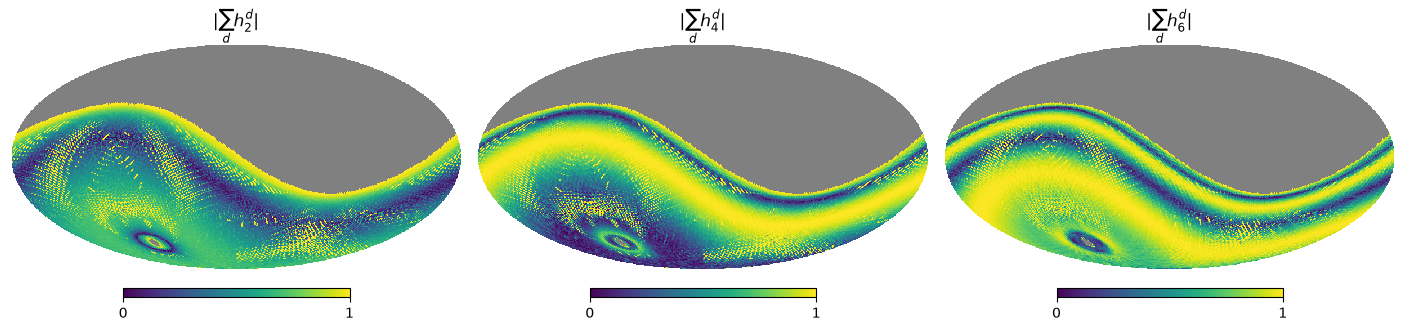

In [10]:
def full_sky(values):
    output = np.full(mask_hits.size, hp.UNSEEN)
    output[mask_hits != 0] = values
    return output

fig = plt.figure(figsize=(14, 3.6))
for i, n in enumerate((2, 4, 6)):
    cross_linking = np.abs(h_maps[n].sum(axis=0))
    hp.mollview(full_sky(cross_linking), sub=(1, 3, i + 1), fig=fig.number, min=0, max=1,
                title=rf"$|\sum_d h^d_{n}|$")
plt.show()

We now set up the SMARTIES `FrameworkSystematics` object. It solves the spin mapmaking equation
pixel by pixel. Without systematics, the output must be the input sky wherever the mapmaking
matrix can be inverted, whatever the scan. The inverse mapmaking matrix only depends on the
$h$-maps and the polarisation angles, so we keep it to reuse it for every systematics run.

In [11]:
syste_object = sm.FrameworkSystematics(
    map_shape=(1, mask_hits.size),
    nstokes=3,
    lmax=lmax,
    list_spin_output=[0, -2, 2],
)

## SMARTIES beam convolution

SMARTIES can ingest the harmonic coefficients $b_{\ell m}$ of each detector beam.
`get_beam_convolution_spins_maps` computes the spin maps of the beam-convolved sky for every
detector. Here `substract_gaussian_beam=False`, so the maps include the full beam rather than
only the deviation from an ideal Gaussian.

In [12]:
# Convert the litebird_sim alms into dictionaries keyed by detector name
alm_sky_smarties = {
    det_name: alm_sky[det_name].values for det_name in list(alm_sky.keys())[:-1]
}
blms_smarties = {det_name: blms[det_name].values for det_name in blms}

# Compute the spin systematics maps induced by the beam
spin_maps_convolution = get_beam_convolution_spins_maps(
    alm_sky_smarties,
    blms_smarties,
    [det.name for det in dets],
    lmax,
    mmax,
    fwhm=fwhm_arcmin,
    shape_pixels_output=(hp.nside2npix(nside),),
    pol_angles_rad=[det.pol_angle_rad for det in dets],
    substract_gaussian_beam=False, # If true the maps will be computed with the Gaussian beam substracted, so that the output maps will only contain the systematics induced by the beam deviations from the ideal Gaussian beam
)

In [13]:
# Keep only the observed pixels
spin_maps_convolution_masked = spin_maps_convolution.copy()
for spin in spin_maps_convolution:
    spin_maps_convolution_masked[spin] = spin_maps_convolution[spin][:, mask_hits != 0]
spin_maps_convolution_masked = sm.Spin_maps.from_dictionary(spin_maps_convolution_masked)
del spin_maps_convolution

Since the sky was convolved with the full beam $b_{\ell m}$, `spin_maps_convolution_masked`
already contains the full beam-convolved signal. The input `spin_sky_maps` is therefore set to
zero: `compute_total_maps` combines the $h$-maps, the beam systematics maps, the mask, and the
detector polarisation angles to reconstruct the total $I$, $Q$, and $U$ maps.

In [14]:
# Combine the h-maps with the beam systematics to get the total maps
empty_sky = sm.transform_array_maps_into_spin_maps( 
    np.zeros((3, np.sum(mask_hits))), n_stokes_output=3
)
final_maps_from_blms, inverse_mapmaking_matrix = syste_object.compute_total_maps(
    h_n_spin_dict=h_maps,
    spin_sky_maps=empty_sky,
    mask=mask_hits,
    spin_systematics_maps=spin_maps_convolution_masked,
    inverse_mapmaking_matrix=None,
    return_Q_U=True,
    return_inverse_mapmaking_matrix=True,
    mask_input=False,
    polar_angle=np.array([det.pol_angle_rad for det in dets]),
)

20-Oct-26 15:55:16 INFO smarties.mapmaking: Starting the computation of the inverse mapmaking matrix...
20-Oct-26 15:55:16 INFO smarties.mapmaking: Inverse mapmaking matrix computed in 0.12 seconds
20-Oct-26 15:55:16 INFO smarties.mapmaking: Computing the spin coupled maps...
20-Oct-26 15:55:16 INFO smarties.mapmaking: Optimizing the computations for the spin convolution...
20-Oct-26 15:55:16 INFO smarties.mapmaking: Coupled spins for spin 0: [(4, -4), (2, -2), (0, 0), (-2, 2), (-4, 4)]
20-Oct-26 15:55:16 INFO smarties.mapmaking: Coupled spins for spin 2: [(6, -4), (4, -2), (2, 0), (0, 2), (-2, 4)]
20-Oct-26 15:55:16 INFO smarties.mapmaking: Spin coupled maps computed in 0.02 seconds, computing the final maps ...
20-Oct-26 15:55:16 INFO smarties.mapmaking: Final maps computed in 0.00 seconds...


## Comparison with `litebird_sim`

The SMARTIES maps should agree with the 4$\pi$ convolution to numerical precision. The residual
maps below show the difference for $I$, $Q$, and $U$, together with the RMS over observed pixels.

In [15]:
# Expand the masked SMARTIES maps back to the full sky
smarties_maps = np.full((3, mask_hits.size), hp.UNSEEN, dtype=float)
for i in range(3):
    smarties_maps[i, mask_hits != 0] = final_maps_from_blms[i].real

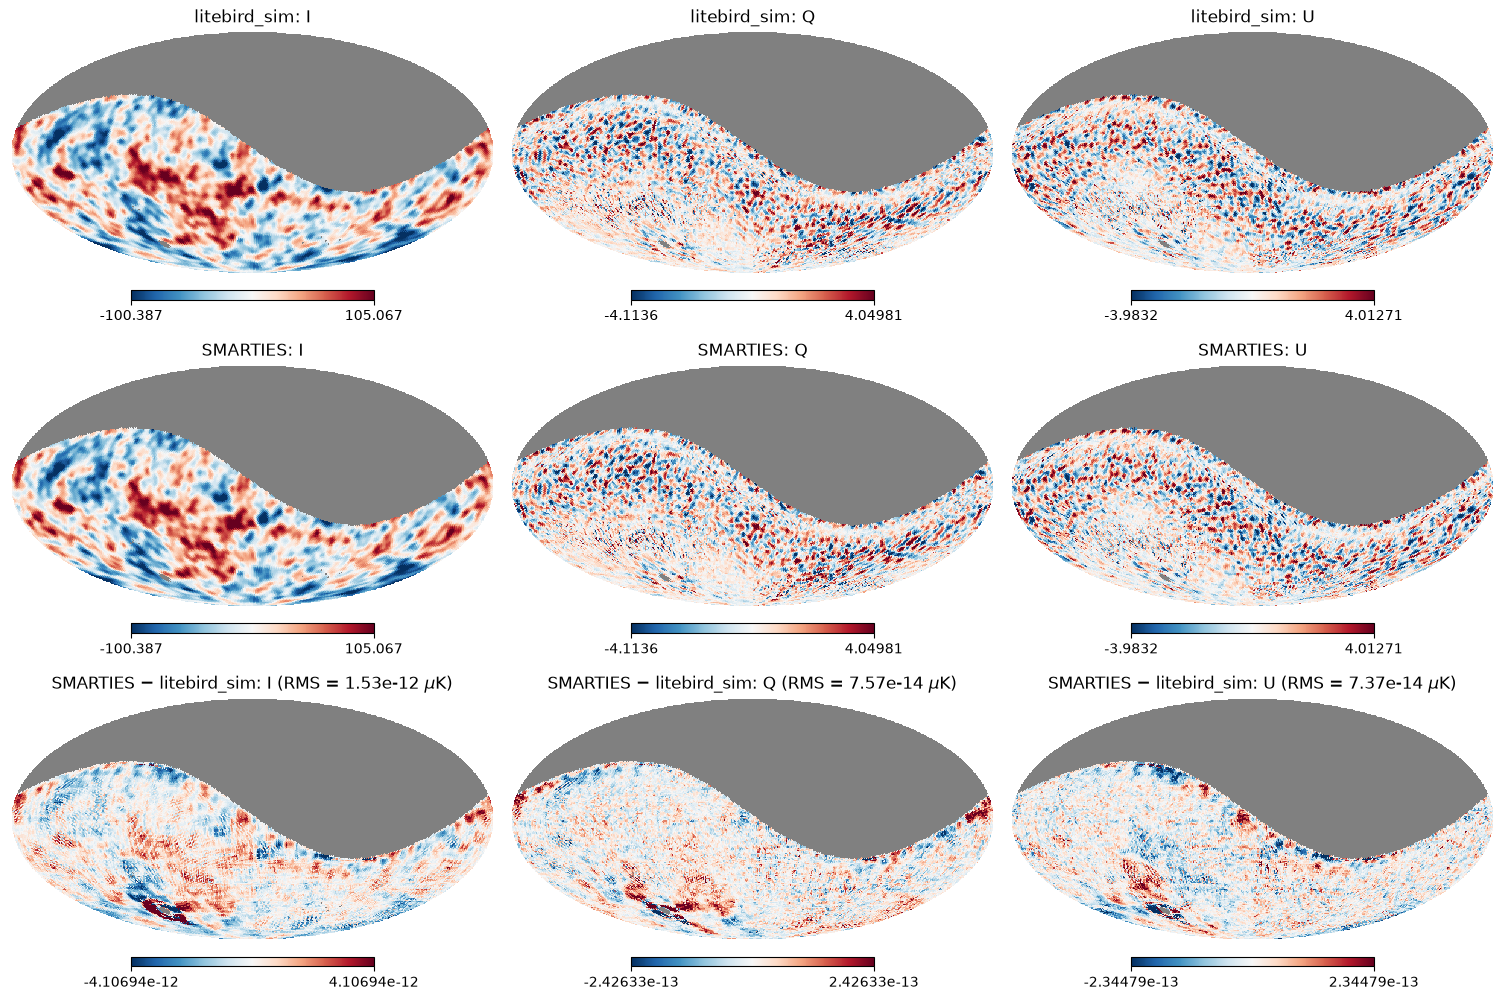

In [17]:
stokes = ("I", "Q", "U")
observed = mask_hits != 0
fig = plt.figure(figsize=(15, 10))

for i_stokes, name in enumerate(stokes):
    lbs_map = np.where(observed, four_pi_convolved_map[i_stokes], hp.UNSEEN)
    sm_map = smarties_maps[i_stokes]
    residual = np.where(observed, sm_map - four_pi_convolved_map[i_stokes], hp.UNSEEN)

    vmin, vmax = np.percentile(lbs_map[observed], [1, 99])
    rmax = max(np.percentile(np.abs(residual[observed]), 99), np.finfo(float).eps)
    rms = np.sqrt(np.mean(residual[observed] ** 2))

    hp.mollview(
        lbs_map, sub=(3, 3, i_stokes + 1), fig=fig.number,
        min=vmin, max=vmax, title=f"litebird_sim: {name}", cmap="RdBu_r",
    )
    hp.mollview(
        sm_map, sub=(3, 3, i_stokes + 4), fig=fig.number,
        min=vmin, max=vmax, title=f"SMARTIES: {name}", cmap="RdBu_r",
    )
    hp.mollview(
        residual, sub=(3, 3, i_stokes + 7), fig=fig.number,
        min=-rmax, max=rmax, cmap="RdBu_r",
        title=rf"SMARTIES $-$ litebird_sim: {name} (RMS = {rms:.2e} $\mu$K)",
    )

plt.show()